# Experiment 11 — M-PSK and M-QAM (first-principles, Python)

Python port of the MATLAB lab script. Only **NumPy** and **Matplotlib** are used; there is no
SciPy, no communications library. Constellation generation, Gray/binary mapping, energy
normalisation, AWGN, minimum-distance detection, BER/SER counting and d_min are all implemented
by hand below.

**Conventions**
* A *position index* `p = 0..M-1` identifies a constellation point (geometry).
* A *label* is the integer whose k-bit form is attached to that point. Gray vs binary changes
  only `label[p]`, never the points.
* BER/SER sweeps use **Eb/N0** with `Es = k*Eb`, `k = log2(M)`; received-constellation plots
  use **Es/N0** (0, 5, 10, 20 dB).
* Complex AWGN: `E|n|^2 = N0`, i.e. variance `N0/2` on each of I and Q.

Run as a script (`python exp11_mpsk_mqam.py`) or open as a notebook. Environment variable
`EXP11_NSYM` overrides the number of symbols per SNR point (default 500000).

In [1]:
import os
import math
import time
import numpy as np
import matplotlib
if not os.environ.get("DISPLAY") and os.name != "nt" and "ipykernel" not in __import__("sys").modules:
    matplotlib.use("Agg")          # headless script run
import matplotlib.pyplot as plt

OUT_DIR = "exp11_figures"
os.makedirs(OUT_DIR, exist_ok=True)
T0 = time.time()

# ---------------------------------------------------------------- parameters
NAMES = ["QPSK", "8-PSK", "16-QAM", "64-QAM"]
TYPES = ["PSK", "PSK", "QAM", "QAM"]
M_LIST = [4, 8, 16, 64]
K_LIST = [int(math.log2(M)) for M in M_LIST]
PSK_A = [math.sqrt(2), 1.0, None, None]   # QPSK -> (+-1 +-j), 8-PSK -> unit circle
PSK_PHASE0 = [math.pi / 4, 0.0, 0.0, 0.0]  # QPSK offset pi/4, 8-PSK exactly A*exp(j*2*pi*p/M)
EBN0_DB = np.arange(0, 21, 2)              # BER/SER sweep
ESN0_RX_DB = [0, 5, 10, 20]                # Task 43
EBN0_SE = [6, 10]                          # BER vs spectral efficiency operating points
NSYM = int(float(os.environ.get("EXP11_NSYM", 5e5)))
NSYM_SE = 4 * NSYM
CHUNK = 20000
N_PLOT = 1500
ES_TARGET = 1.0
COLORS = ["#0072BD", "#D95319", "#77AC30", "#7E2F8E"]
MARKERS = ["o", "s", "^", "d"]
CHECKS = []                                # (description, passed)


def check(text, ok):
    CHECKS.append((text, bool(ok)))


print("=== EXPERIMENT 11 : M-PSK AND M-QAM ===")
print(f"Symbols per SNR point = {NSYM:g}, chunk = {CHUNK}")

=== EXPERIMENT 11 : M-PSK AND M-QAM ===
Symbols per SNR point = 500000, chunk = 20000


## Building blocks (all hand-written)

In [2]:
def generate_mpsk(M, A, phase0):
    """s_p = A exp(j(2*pi*p/M + phase0)), p = 0..M-1."""
    p = np.arange(M)
    return A * np.exp(1j * (2 * np.pi * p / M + phase0))


def generate_qam(M):
    """Square M-QAM, levels +-1,+-3,...,+-(sqrt(M)-1). Position p = iI*sqrt(M) + iQ."""
    sq = int(round(math.sqrt(M)))
    if sq * sq != M:
        raise ValueError("M must be a perfect square")
    p = np.arange(M)
    iI, iQ = p // sq, p % sq
    lev = np.arange(-(sq - 1), sq, 2)
    return lev[iI] + 1j * lev[iQ]


def gray_code(n):
    """Binary-reflected Gray code g(i) = i XOR (i >> 1), i = 0..2^n-1."""
    b = np.arange(2 ** n)
    return b ^ (b >> 1)


def make_labels(kind, M):
    """Return (gray_label, binary_label) arrays indexed by constellation position."""
    k = int(math.log2(M))
    p = np.arange(M)
    if kind == "PSK":
        return gray_code(k)[p], p.copy()
    sq = int(round(math.sqrt(M)))
    nb = k // 2
    iI, iQ = p // sq, p % sq
    g = gray_code(nb)
    return g[iI] * sq + g[iQ], iI * sq + iQ    # [Gray(I)|Gray(Q)] and [bin(I)|bin(Q)]


def normalize_constellation(s, es_target=1.0):
    """ONE common factor for the whole constellation (average-energy normalisation)."""
    e_before = np.mean(np.abs(s) ** 2)
    factor = math.sqrt(es_target / e_before)
    sn = factor * s
    return sn, factor, e_before, np.mean(np.abs(sn) ** 2)


def calculate_dmin(s):
    """Minimum distance over all distinct pairs, from the points themselves."""
    D = np.abs(s[:, None] - s[None, :])
    np.fill_diagonal(D, np.inf)
    dmin = D.min()
    return dmin, int(np.sum(np.abs(D - dmin) < 1e-9) // 2)


def hamming(a, b):
    return bin(int(a) ^ int(b)).count("1")


def nn_hamming(s, lab):
    """Hamming distance between labels of NEAREST-NEIGHBOUR constellation points."""
    D = np.abs(s[:, None] - s[None, :])
    np.fill_diagonal(D, np.inf)
    dmin = D.min()
    pairs = np.argwhere(np.triu(np.abs(D - dmin) < 1e-9))
    h = np.array([hamming(lab[a], lab[b]) for a, b in pairs])
    return len(pairs), int(h.max()), float(h.mean())


def minimum_distance_detector(r, s):
    """idx[n] = argmin_i |r[n]-s_i|^2 (0-based position). Generic for any constellation s."""
    r = np.asarray(r).ravel()
    d = (r.real[:, None] - s.real[None, :]) ** 2 + (r.imag[:, None] - s.imag[None, :]) ** 2
    return np.argmin(d, axis=1)


def detect_chunked(r, s, chunk=CHUNK):
    r = np.asarray(r).ravel()
    return np.concatenate([minimum_distance_detector(r[a:a + chunk], s) for a in range(0, r.size, chunk)])


def add_awgn(x, N0, rng):
    """Complex AWGN with E|n|^2 = N0 (variance N0/2 on I and on Q)."""
    n = math.sqrt(N0 / 2) * (rng.standard_normal(x.shape) + 1j * rng.standard_normal(x.shape))
    return x + n, n


def simulate_link(s, lab, k, ebn0_db, nsym, seed, chunk=CHUNK):
    """bits -> label -> position -> symbol -> AWGN(Eb/N0) -> min-distance -> label -> bits.
    Returns BER, SER, #bit errors, #symbol errors, measured noise power E|n|^2."""
    rng = np.random.default_rng(seed)
    M = s.size
    Es = np.mean(np.abs(s) ** 2)
    Eb = Es / k                                   # Es = k*Eb
    N0 = 0.0 if np.isinf(ebn0_db) else Eb / 10 ** (ebn0_db / 10)
    pos_of_label = np.empty(M, dtype=int)
    pos_of_label[lab] = np.arange(M)
    shifts = np.arange(k - 1, -1, -1)             # MSB first
    weights = 2 ** shifts
    n_be = n_se = done = 0
    pw = 0.0
    while done < nsym:
        n = min(chunk, nsym - done)
        bits = rng.integers(0, 2, size=(n, k))    # transmitted bits
        pos_t = pos_of_label[bits @ weights]
        rx, nz = add_awgn(s[pos_t], N0, rng)
        pos_r = minimum_distance_detector(rx, s)
        bits_r = (lab[pos_r][:, None] >> shifts) & 1
        assert bits.shape == bits_r.shape
        n_be += int(np.sum(bits != bits_r))       # BER counter
        n_se += int(np.sum(pos_r != pos_t))       # SER counter (independent)
        pw += float(np.sum(np.abs(nz) ** 2))
        done += n
    return n_be / (nsym * k), n_se / nsym, n_be, n_se, pw / nsym


def qfun(x):
    return 0.5 * np.vectorize(math.erfc)(np.asarray(x, dtype=float) / math.sqrt(2))


def theory_curves(kind, M, ebn0_db):
    """Textbook AWGN/coherent/Gray results. QPSK exact; M-PSK(M>4) and QAM BER are APPROXIMATIONS."""
    g = 10 ** (np.asarray(ebn0_db, dtype=float) / 10)
    k = math.log2(M)
    if kind == "PSK":
        if M == 4:
            q = qfun(np.sqrt(2 * g))
            return q, 2 * q - q ** 2
        ser = 2 * qfun(np.sqrt(2 * k * g) * math.sin(math.pi / M))
        return ser / k, ser
    qq = qfun(np.sqrt(3 * k * g / (M - 1)))
    ps = 2 * (1 - 1 / math.sqrt(M)) * qq
    return (4 / k) * (1 - 1 / math.sqrt(M)) * qq, 2 * ps - ps ** 2   # 2p-p^2 avoids cancellation


def savefig(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name + ".png"), dpi=110, bbox_inches="tight")

## Constellations, mapping, normalisation, d_min

In [3]:
C = []
for m in range(4):
    M, k, kind = M_LIST[m], K_LIST[m], TYPES[m]
    if kind == "PSK":
        raw = generate_mpsk(M, PSK_A[m], PSK_PHASE0[m])
        es_an, fac_an = PSK_A[m] ** 2, 1 / PSK_A[m]
        dmin_th = 2 * math.sqrt(ES_TARGET) * math.sin(math.pi / M)
    else:
        raw = generate_qam(M)
        es_an = 2 * (M - 1) / 3
        fac_an = 1 / math.sqrt(es_an)
        dmin_th = math.sqrt(6 * ES_TARGET / (M - 1))
    pts, fac, e_bef, e_aft = normalize_constellation(raw, ES_TARGET)
    labG, labB = make_labels(kind, M)
    dmin, n_dpairs = calculate_dmin(pts)
    npair, maxHG, meanHG = nn_hamming(pts, labG)
    _, maxHB, meanHB = nn_hamming(pts, labB)
    C.append(dict(name=NAMES[m], M=M, k=k, kind=kind, raw=raw, pts=pts, labG=labG, labB=labB,
                  e_bef=e_bef, e_aft=e_aft, fac=fac, es_an=es_an, fac_an=fac_an,
                  dmin=dmin, dmin_th=dmin_th, n_dpairs=n_dpairs,
                  npair=npair, maxHG=maxHG, meanHG=meanHG, maxHB=maxHB, meanHB=meanHB))
    check(f"{NAMES[m]} has exactly {M} points", pts.size == M)
    check(f"{NAMES[m]} all points distinct (d_min>0)", dmin > 0)
    check(f"{NAMES[m]} Gray/binary labels are permutations of 0..M-1",
          np.array_equal(np.sort(labG), np.arange(M)) and np.array_equal(np.sort(labB), np.arange(M)))

print("\n---- MANDATORY ENERGY-NORMALISATION VALIDATION (target Es = 1) ----")
print(f"{'Mod':8s} {'M':>3s} | {'Es before':>12s} {'Es analytic':>12s} | {'Norm factor':>14s} "
      f"{'Factor analyt.':>14s} | {'Es after':>16s} | |Es after-1|")
for c in C:
    print(f"{c['name']:8s} {c['M']:3d} | {c['e_bef']:12.6f} {c['es_an']:12.6f} | {c['fac']:14.8f} "
          f"{c['fac_an']:14.8f} | {c['e_aft']:16.12f} | {abs(c['e_aft'] - ES_TARGET):.2e}")
    check(f"{c['name']}: Es after normalisation = 1 (tol 1e-12)", abs(c["e_aft"] - 1) < 1e-12)
    check(f"{c['name']}: numeric Es/factor match analytic (tol 1e-12)",
          abs(c["e_bef"] - c["es_an"]) < 1e-12 and abs(c["fac"] - c["fac_an"]) < 1e-12)
for c in C[2:]:
    pk = np.max(np.abs(c["pts"]))
    print(f"{c['name']}: raw peak |s|={np.max(np.abs(c['raw'])):.4f}, normalised peak |s|={pk:.4f}")

print("\n---- MINIMUM EUCLIDEAN DISTANCE (normalised, Es = 1) ----")
print(f"{'Mod':8s} {'M':>3s} {'Es':>5s} | {'d_min num':>10s} {'d_min theo':>10s} {'abs diff':>9s} | nearest pairs")
for c in C:
    print(f"{c['name']:8s} {c['M']:3d} {np.mean(np.abs(c['pts'])**2):5.2f} | {c['dmin']:10.6f} "
          f"{c['dmin_th']:10.6f} {abs(c['dmin'] - c['dmin_th']):9.1e} | {c['n_dpairs']}")
    check(f"{c['name']}: numeric d_min equals closed form (tol 1e-12)", abs(c["dmin"] - c["dmin_th"]) < 1e-12)

print("\n---- GRAY vs BINARY: Hamming distance across NEAREST-NEIGHBOUR pairs ----")
for c in C:
    print(f"{c['name']:8s} pairs={c['npair']:4d} | Gray max/mean = {c['maxHG']}/{c['meanHG']:.4f} "
          f"| Binary max/mean = {c['maxHB']}/{c['meanHB']:.4f}")
    check(f"{c['name']}: Gray labels differ in exactly 1 bit for every nearest pair",
          c["maxHG"] == 1 and abs(c["meanHG"] - 1) < 1e-12)
    check(f"{c['name']}: binary labels are different from Gray labels",
          np.any(c["labG"] != c["labB"]) and c["meanHB"] > 1)

for c in C[:3]:
    print(f"\nMapping table: {c['name']}  (p, normalised point, Gray, binary)")
    for p in range(c["M"]):
        z = c["pts"][p]
        print(f"  p={p:2d}  {z.real:+8.4f} {z.imag:+8.4f}j   Gray={c['labG'][p]:0{c['k']}b}   "
              f"Binary={c['labB'][p]:0{c['k']}b}")


---- MANDATORY ENERGY-NORMALISATION VALIDATION (target Es = 1) ----
Mod        M |    Es before  Es analytic |    Norm factor Factor analyt. |         Es after | |Es after-1|
QPSK       4 |     2.000000     2.000000 |     0.70710678     0.70710678 |   1.000000000000 | 0.00e+00
8-PSK      8 |     1.000000     1.000000 |     1.00000000     1.00000000 |   1.000000000000 | 0.00e+00
16-QAM    16 |    10.000000    10.000000 |     0.31622777     0.31622777 |   1.000000000000 | 3.33e-16
64-QAM    64 |    42.000000    42.000000 |     0.15430335     0.15430335 |   1.000000000000 | 2.22e-16
16-QAM: raw peak |s|=4.2426, normalised peak |s|=1.3416
64-QAM: raw peak |s|=9.8995, normalised peak |s|=1.5275

---- MINIMUM EUCLIDEAN DISTANCE (normalised, Es = 1) ----
Mod        M    Es |  d_min num d_min theo  abs diff | nearest pairs
QPSK       4  1.00 |   1.414214   1.414214   0.0e+00 | 4
8-PSK      8  1.00 |   0.765367   0.765367   1.1e-16 | 8
16-QAM    16  1.00 |   0.632456   0.632456   1.1e-16 | 24


## Receiver self-tests and Eb/N0 / noise-variance scaling check

In [4]:
print("\n---- RECEIVER SELF-TESTS ----")
rng_t = np.random.default_rng(123)
for c in C:
    rt = 1.5 * (rng_t.standard_normal(5000) + 1j * rng_t.standard_normal(5000))
    idx = minimum_distance_detector(rt, c["pts"])
    idx_ref = np.array([np.argmin(np.abs(r - c["pts"]) ** 2) for r in rt])   # explicit d_i loop
    ok_det = np.array_equal(idx, idx_ref)
    bG, sG, *_ = simulate_link(c["pts"], c["labG"], c["k"], np.inf, 100000, 1)
    bB, sB, *_ = simulate_link(c["pts"], c["labB"], c["k"], np.inf, 100000, 1)
    print(f"{c['name']:8s} detector==loop: {int(ok_det)} | zero-noise Gray BER={bG:g} SER={sG:g} "
          f"| binary BER={bB:g} SER={sB:g}")
    check(f"{c['name']}: min-distance detector equals brute-force loop", ok_det)
    check(f"{c['name']}: zero-noise run recovers all labels (BER=SER=0, both maps)",
          bG == 0 and sG == 0 and bB == 0 and sB == 0)

print("\n---- Eb/N0 SCALING AND COMPLEX-NOISE VARIANCE (Eb/N0 = 10 dB) ----")
print(f"{'Mod':8s} {'k':>2s} | {'Es':>6s} {'Eb=Es/k':>9s} {'N0':>9s} | {'E|n|^2 meas':>12s} "
      f"{'N0 expected':>12s} | {'Es/N0 dB':>9s} {'expected':>9s}")
for c in C:
    Es = np.mean(np.abs(c["pts"]) ** 2)
    N0 = Es / c["k"] / 10 ** (10 / 10)
    *_, nv = simulate_link(c["pts"], c["labG"], c["k"], 10, 200000, 5)
    print(f"{c['name']:8s} {c['k']:2d} | {Es:6.3f} {Es / c['k']:9.5f} {N0:9.5f} | {nv:12.6f} {N0:12.6f} "
          f"| {10 * np.log10(Es / nv):9.3f} {10 + 10 * np.log10(c['k']):9.3f}")
    check(f"{c['name']}: measured noise variance within 1% of N0", abs(nv / N0 - 1) < 0.01)


---- RECEIVER SELF-TESTS ----
QPSK     detector==loop: 1 | zero-noise Gray BER=0 SER=0 | binary BER=0 SER=0
8-PSK    detector==loop: 1 | zero-noise Gray BER=0 SER=0 | binary BER=0 SER=0


16-QAM   detector==loop: 1 | zero-noise Gray BER=0 SER=0 | binary BER=0 SER=0


64-QAM   detector==loop: 1 | zero-noise Gray BER=0 SER=0 | binary BER=0 SER=0

---- Eb/N0 SCALING AND COMPLEX-NOISE VARIANCE (Eb/N0 = 10 dB) ----
Mod       k |     Es   Eb=Es/k        N0 |  E|n|^2 meas  N0 expected |  Es/N0 dB  expected
QPSK      2 |  1.000   0.50000   0.05000 |     0.049932     0.050000 |    13.016    13.010
8-PSK     3 |  1.000   0.33333   0.03333 |     0.033305     0.033333 |    14.775    14.771
16-QAM    4 |  1.000   0.25000   0.02500 |     0.025056     0.025000 |    16.011    16.021


64-QAM    6 |  1.000   0.16667   0.01667 |     0.016649     0.016667 |    17.786    17.782


## Figures 1–3: ideal constellations, Gray vs binary labels, decision regions

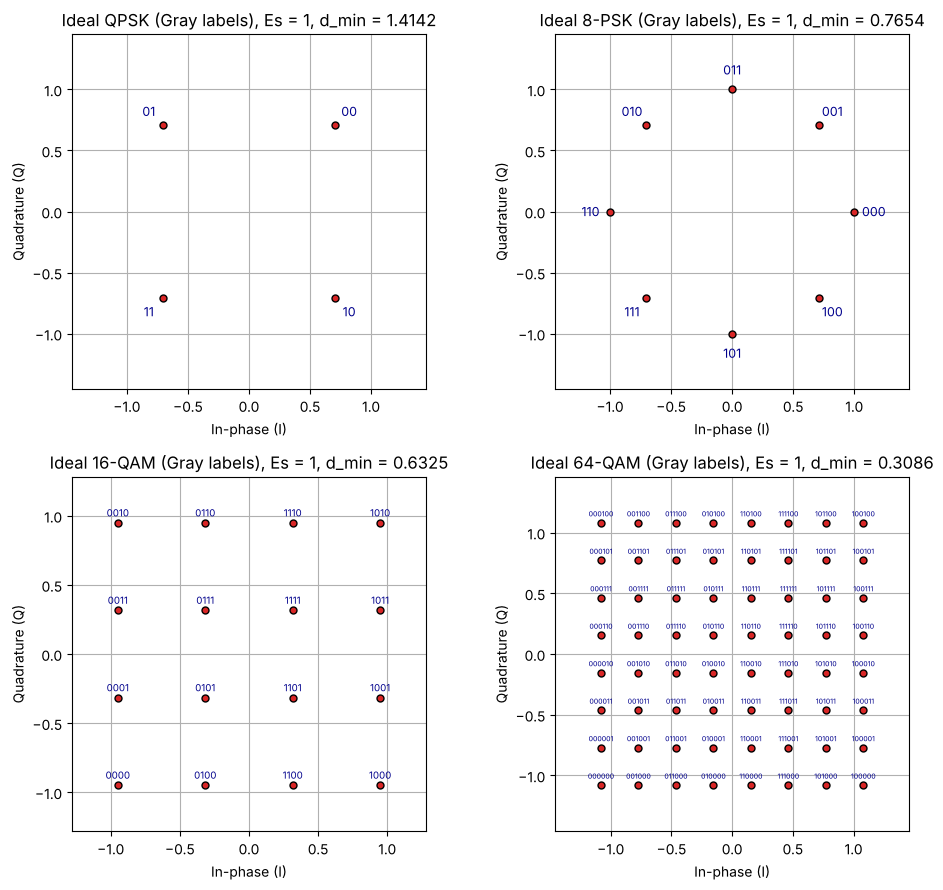

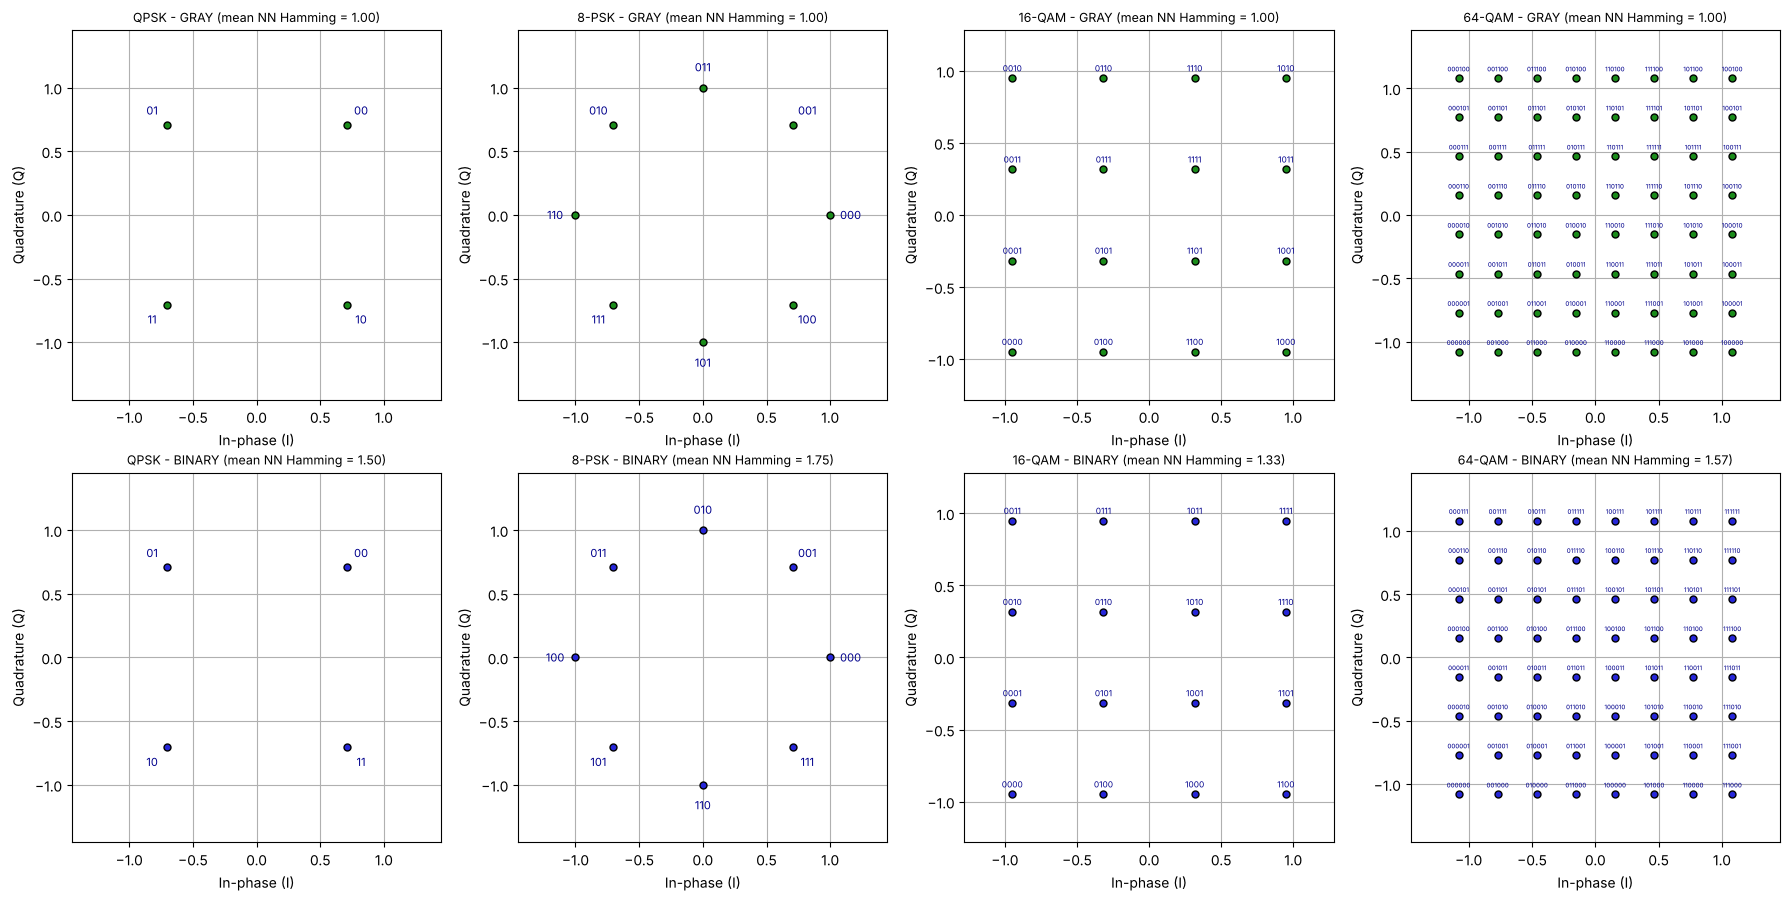

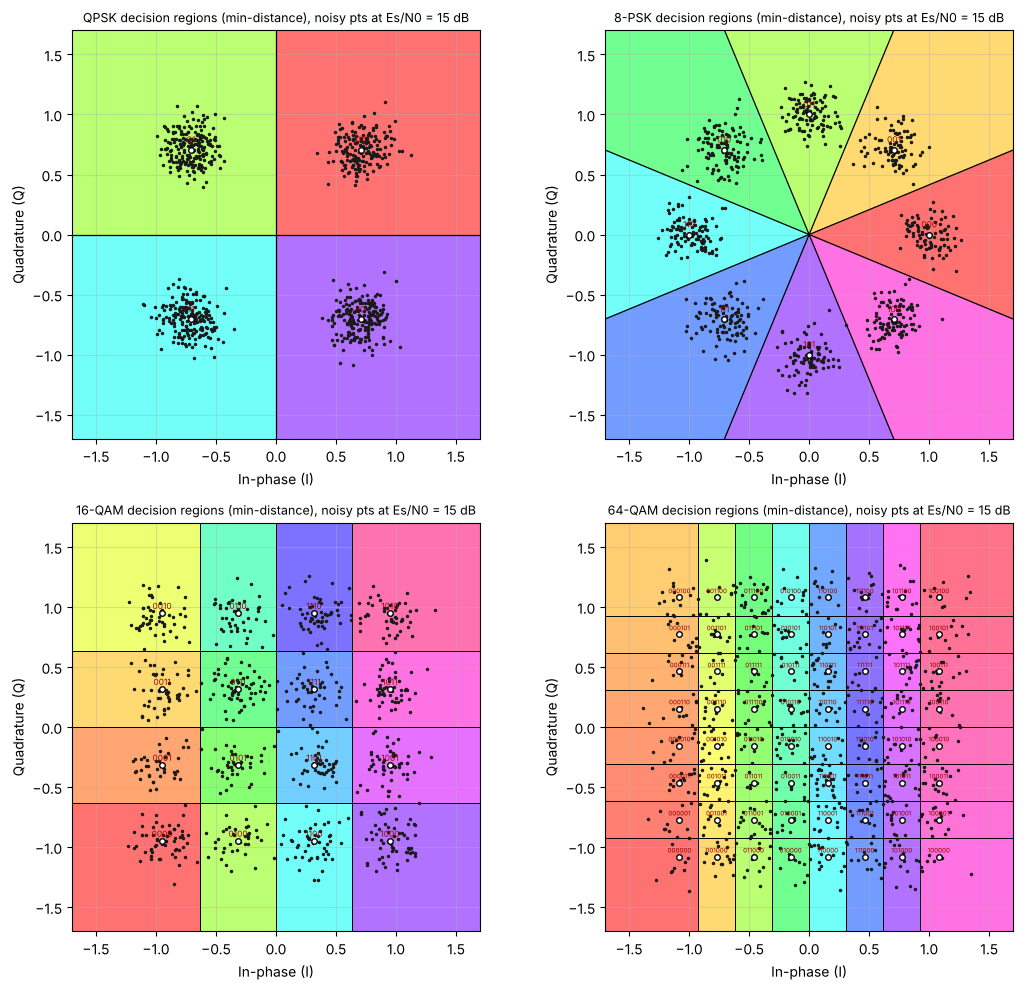

In [5]:
def draw_const(ax, c, lab, color, fs):
    pts, k = c["pts"], c["k"]
    ax.plot(pts.real, pts.imag, "o", ms=5, mfc=color, mec="k")
    mx = np.max(np.abs(np.r_[pts.real, pts.imag]))
    for p in range(c["M"]):
        txt = f"{lab[p]:0{k}b}"
        if c["kind"] == "PSK":
            t = 1.16 * pts[p]
            ax.text(t.real, t.imag, txt, fontsize=fs + 2, ha="center", va="center", color="#00008c")
        else:
            ax.text(pts[p].real, pts[p].imag + 0.05 * mx, txt, fontsize=fs, ha="center", color="#00008c")
    lim = 1.45 if c["kind"] == "PSK" else 1.35 * mx
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(True)
    ax.set_xlabel("In-phase (I)"); ax.set_ylabel("Quadrature (Q)")


fig, axs = plt.subplots(2, 2, figsize=(10, 9))
for m, ax in enumerate(axs.ravel()):
    draw_const(ax, C[m], C[m]["labG"], "#d92626", 7 - 2 * (m == 3))
    ax.set_title(f"Ideal {C[m]['name']} (Gray labels), Es = 1, d_min = {C[m]['dmin']:.4f}")
fig.tight_layout(); savefig(fig, "Fig01_Ideal_Constellations_Gray"); plt.show()

fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for m in range(4):
    draw_const(axs[0, m], C[m], C[m]["labG"], "#1a8c1a", 6 - 1.5 * (m == 3))
    axs[0, m].set_title(f"{C[m]['name']} - GRAY (mean NN Hamming = {C[m]['meanHG']:.2f})", fontsize=9)
    draw_const(axs[1, m], C[m], C[m]["labB"], "#2626d9", 6 - 1.5 * (m == 3))
    axs[1, m].set_title(f"{C[m]['name']} - BINARY (mean NN Hamming = {C[m]['meanHB']:.2f})", fontsize=9)
fig.tight_layout(); savefig(fig, "Fig02_Gray_vs_Binary_Labels"); plt.show()

# decision regions: coloured by the SAME minimum_distance_detector on a dense grid
fig, axs = plt.subplots(2, 2, figsize=(11, 10))
lim, nx = 1.7, 400
xg = np.linspace(-lim, lim, nx)
XX, YY = np.meshgrid(xg, xg)
for m, ax in enumerate(axs.ravel()):
    c = C[m]
    zi = detect_chunked((XX + 1j * YY).ravel(), c["pts"]).reshape(nx, nx)
    cm = 0.45 + 0.55 * matplotlib.colormaps["hsv"](np.linspace(0, 1, c["M"], endpoint=False))[:, :3]
    ax.imshow(cm[zi], origin="lower", extent=[-lim, lim, -lim, lim], interpolation="nearest")
    if c["kind"] == "QAM":                                   # midpoints between neighbouring levels
        sq = int(round(math.sqrt(c["M"])))
        lev = np.arange(-(sq - 1), sq, 2) / math.sqrt(2 * (c["M"] - 1) / 3)
        for mid in (lev[:-1] + lev[1:]) / 2:
            ax.axvline(mid, color="k", lw=0.7); ax.axhline(mid, color="k", lw=0.7)
    else:                                                    # bisectors between adjacent phases
        for q in range(c["M"]):
            ang = 2 * np.pi * (q + 0.5) / c["M"] + PSK_PHASE0[m]
            ax.plot([0, 2.5 * np.cos(ang)], [0, 2.5 * np.sin(ang)], "k-", lw=0.9)
    rng_p = np.random.default_rng(500 + m)
    pr = rng_p.integers(0, c["M"], 800)
    rx, _ = add_awgn(c["pts"][pr], 1 / 10 ** (15 / 10), rng_p)
    ax.plot(rx.real, rx.imag, ".", color="#1a1a1a", ms=3)
    ax.plot(c["pts"].real, c["pts"].imag, "o", ms=4, mfc="w", mec="k")
    for p in range(c["M"]):
        ax.text(c["pts"][p].real, c["pts"][p].imag + (0.06 if m < 2 else 0.035), f"{c['labG'][p]:0{c['k']}b}",
                fontsize=6 - 1.5 * (m == 3), ha="center", color="#990000")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(True, alpha=0.4)
    ax.set_xlabel("In-phase (I)"); ax.set_ylabel("Quadrature (Q)")
    ax.set_title(f"{c['name']} decision regions (min-distance), noisy pts at Es/N0 = 15 dB", fontsize=9)
fig.tight_layout(); savefig(fig, "Fig03_Decision_Regions"); plt.show()

## Figures 4–7: received constellations at Es/N0 = 0, 5, 10, 20 dB (Task 43)


---- RECEIVED CONSTELLATIONS: SER on plotted symbols / SER of long run / BER of long run ----
(Eb/N0 = Es/N0 - 10log10(k))


QPSK    | Es/N0= 0: 3.307e-01/2.913e-01/1.582e-01 | Es/N0= 5: 6.200e-02/7.499e-02/3.821e-02 | Es/N0=10: 1.333e-03/1.518e-03/7.590e-04 | Es/N0=20: 0.000e+00/0.000e+00/0.000e+00 |


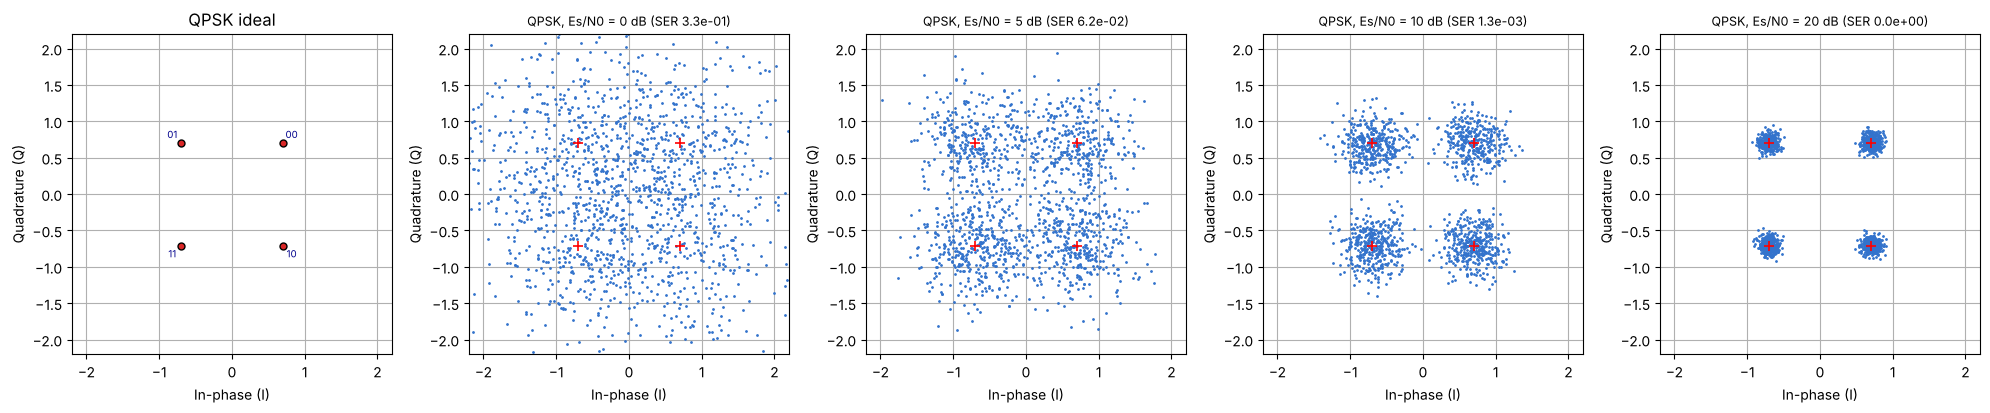

8-PSK   | Es/N0= 0: 5.953e-01/5.769e-01/2.414e-01 | Es/N0= 5: 3.393e-01/3.345e-01/1.173e-01 | Es/N0=10: 8.800e-02/8.603e-02/2.869e-02 | Es/N0=20: 0.000e+00/0.000e+00/0.000e+00 |


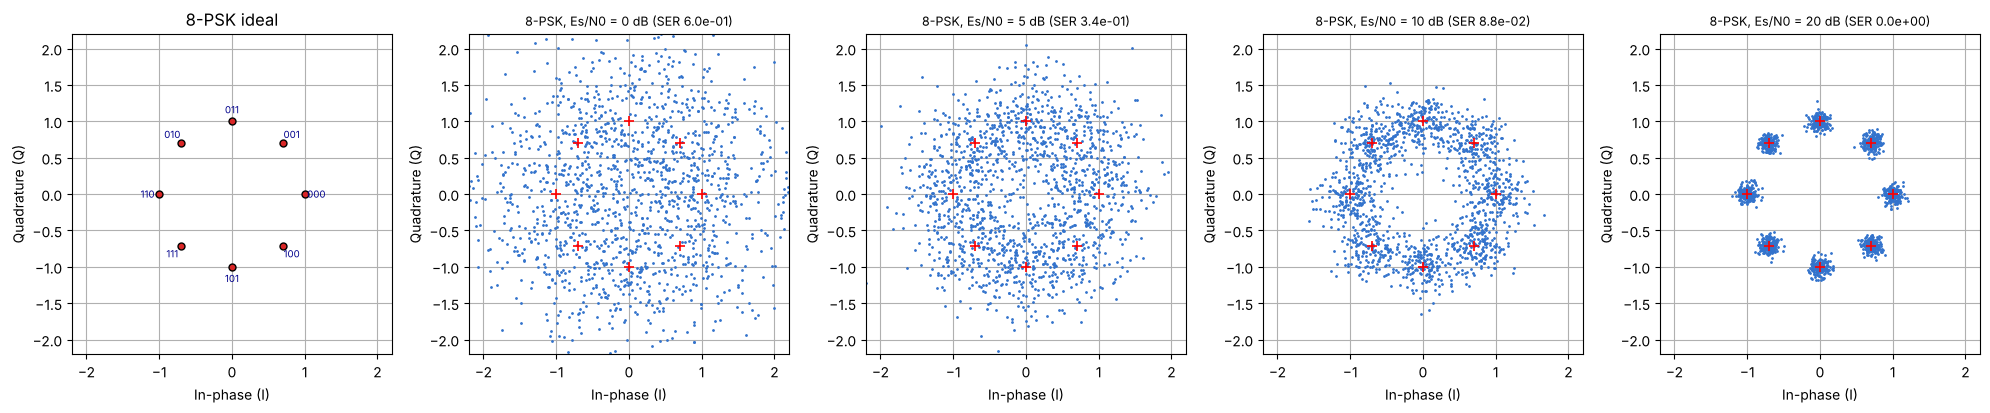

16-QAM  | Es/N0= 0: 7.193e-01/7.412e-01/2.871e-01 | Es/N0= 5: 5.320e-01/5.389e-01/1.645e-01 | Es/N0=10: 2.353e-01/2.226e-01/5.912e-02 | Es/N0=20: 0.000e+00/1.400e-05/3.500e-06 |


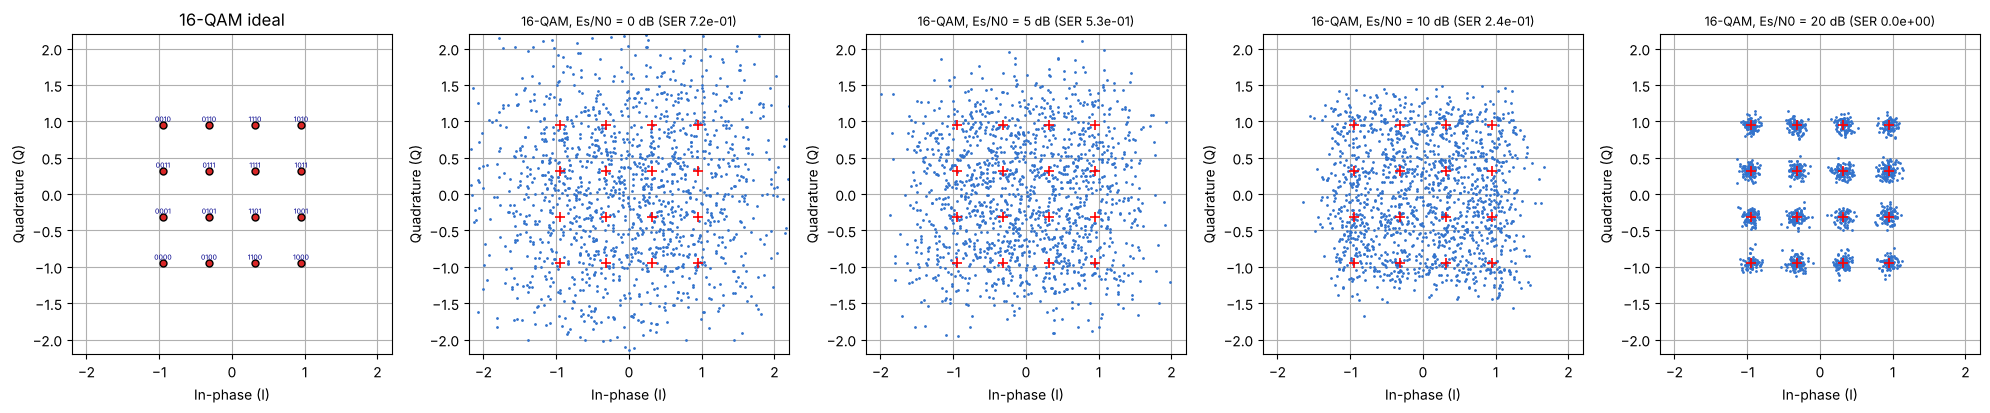

64-QAM  | Es/N0= 0: 9.120e-01/9.239e-01/3.600e-01 | Es/N0= 5: 8.500e-01/8.477e-01/2.623e-01 | Es/N0=10: 6.633e-01/6.740e-01/1.528e-01 | Es/N0=20: 5.800e-02/4.997e-02/8.445e-03 |


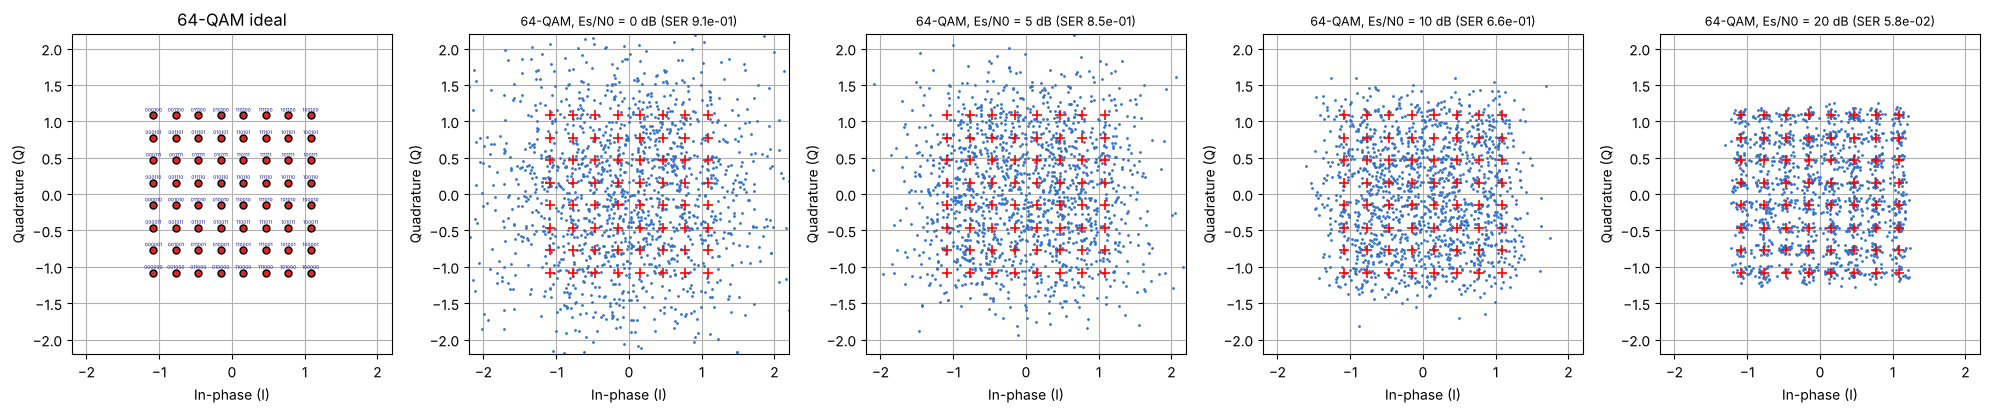

In [6]:
print("\n---- RECEIVED CONSTELLATIONS: SER on plotted symbols / SER of long run / BER of long run ----")
print("(Eb/N0 = Es/N0 - 10log10(k))")
for m, c in enumerate(C):
    fig, axs = plt.subplots(1, 5, figsize=(20, 4.2))
    draw_const(axs[0], c, c["labG"], "#d92626", 5 - 1.5 * (m == 3))
    axs[0].set_title(f"{c['name']} ideal"); axs[0].set_xlim(-2.2, 2.2); axs[0].set_ylim(-2.2, 2.2)
    row = f"{c['name']:8s}|"
    for q, esn0 in enumerate(ESN0_RX_DB):
        rng_r = np.random.default_rng(900 + 10 * (m + 1) + q + 1)
        N0 = np.mean(np.abs(c["pts"]) ** 2) / 10 ** (esn0 / 10)         # Es/N0 definition
        pp = rng_r.integers(0, c["M"], N_PLOT)
        rx, _ = add_awgn(c["pts"][pp], N0, rng_r)
        ser_plot = np.mean(minimum_distance_detector(rx, c["pts"]) != pp)
        ber_r, ser_r, *_ = simulate_link(c["pts"], c["labG"], c["k"], esn0 - 10 * math.log10(c["k"]),
                                         NSYM, 7000 + 10 * m + q)
        row += f" Es/N0={esn0:2d}: {ser_plot:.3e}/{ser_r:.3e}/{ber_r:.3e} |"
        ax = axs[1 + q]
        ax.plot(rx.real, rx.imag, ".", color="#3373cc", ms=2)
        ax.plot(c["pts"].real, c["pts"].imag, "r+", ms=7, mew=1.2)
        ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal"); ax.grid(True)
        ax.set_xlabel("In-phase (I)"); ax.set_ylabel("Quadrature (Q)")
        ax.set_title(f"{c['name']}, Es/N0 = {esn0} dB (SER {ser_plot:.1e})", fontsize=9)
    print(row)
    fig.tight_layout(); savefig(fig, f"Fig{4 + m:02d}_Received_{c['name'].replace('-', '')}"); plt.show()

## BER / SER vs Eb/N0 — Gray and binary (same bit stream and same noise per SNR point)

finished QPSK sweep (16.0 s elapsed)


finished 8-PSK sweep (18.2 s elapsed)


finished 16-QAM sweep (21.7 s elapsed)


finished 64-QAM sweep (33.9 s elapsed)

---- BER / SER vs Eb/N0 (simulated; theory = standard Gray approximations) ----
QPSK  (N = 500000 symbols = 1e+06 bits per point)
  Eb/N0 | BER Gray   BER binary | SER Gray   SER binary | BER theory SER theory | bit errs(G)
    0.0 | 7.888e-02  1.123e-01 | 1.516e-01  1.518e-01 | 7.865e-02  1.511e-01 | 78884
    2.0 | 3.774e-02  5.531e-02 | 7.416e-02  7.396e-02 | 3.751e-02  7.361e-02 | 37743
    4.0 | 1.254e-02  1.858e-02 | 2.490e-02  2.474e-02 | 1.250e-02  2.485e-02 | 12537
    6.0 | 2.421e-03  3.639e-03 | 4.838e-03  4.864e-03 | 2.388e-03  4.771e-03 | 2421
    8.0 | 1.930e-04  2.890e-04 | 3.860e-04  3.840e-04 | 1.909e-04  3.818e-04 | 193
   10.0 | 7.000e-06  9.000e-06 | 1.400e-05  1.200e-05 | 3.872e-06  7.744e-06 | 7
   12.0 | 0.000e+00  0.000e+00 | 0.000e+00  0.000e+00 | 9.006e-09  1.801e-08 | 0
   14.0 | 0.000e+00  0.000e+00 | 0.000e+00  0.000e+00 | 6.810e-13  1.362e-12 | 0
   16.0 | 0.000e+00  0.000e+00 | 0.000e+00  0.000e+00 | 2.267e-19  4.53

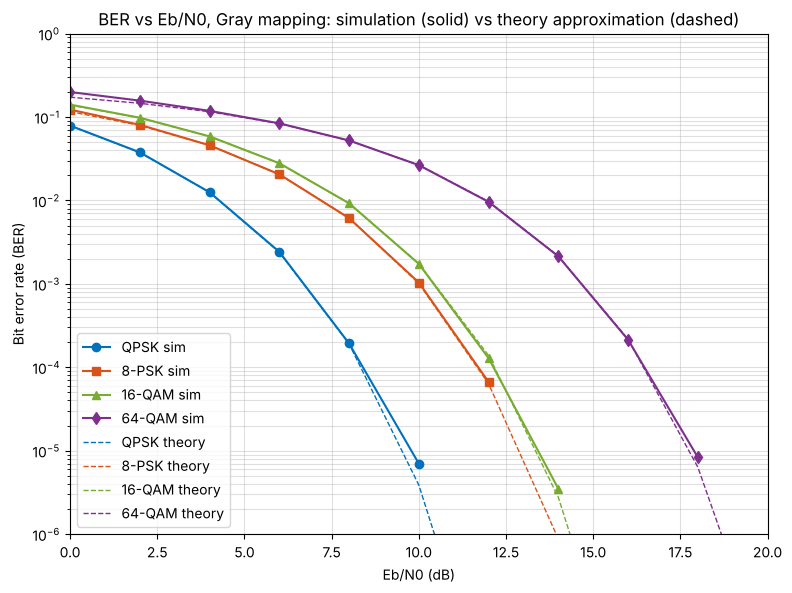

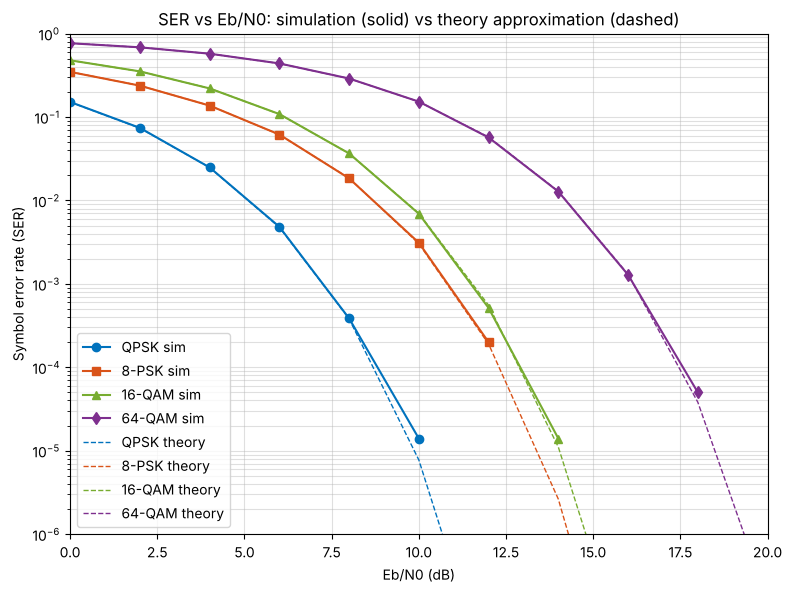

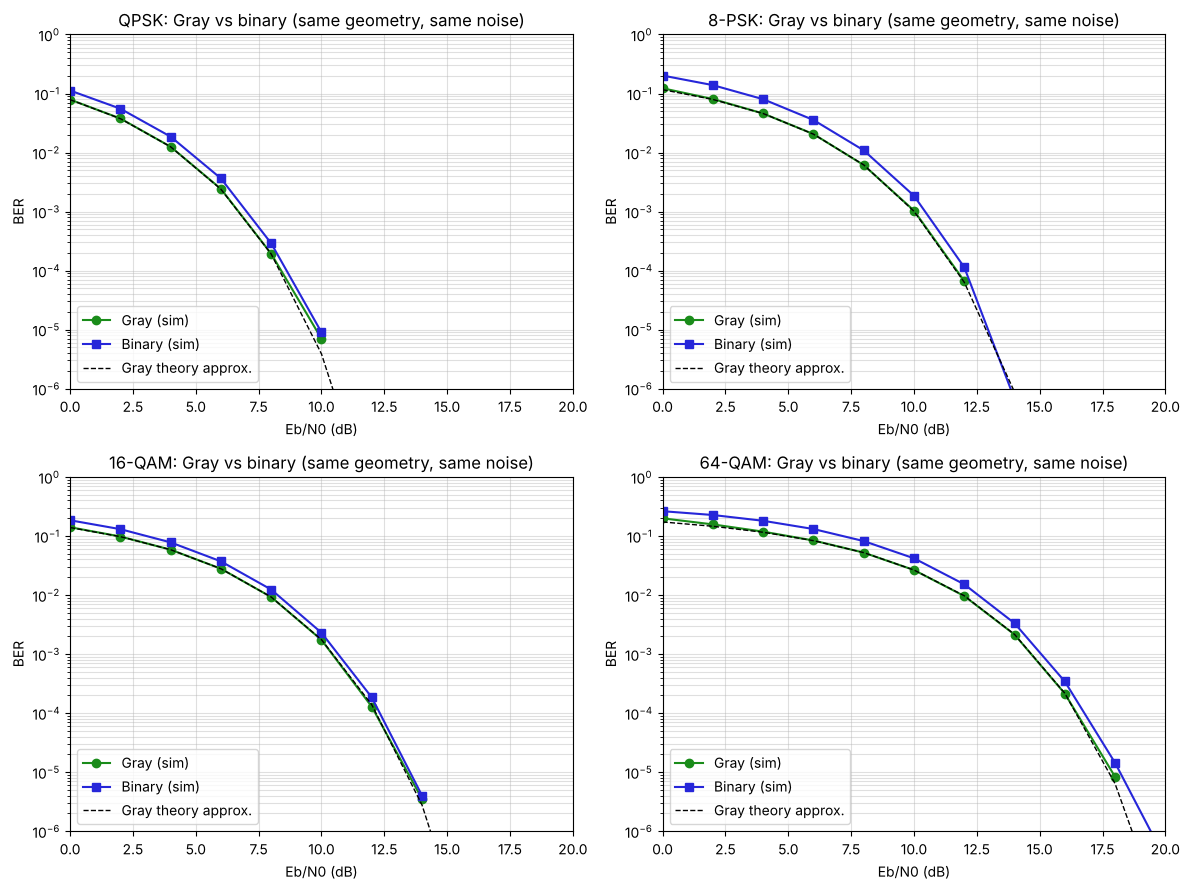

In [7]:
nS = len(EBN0_DB)
BERg = np.zeros((4, nS)); SERg = np.zeros((4, nS)); BERb = np.zeros((4, nS)); SERb = np.zeros((4, nS))
BEg = np.zeros((4, nS), int); SEg = np.zeros((4, nS), int); BEb = np.zeros((4, nS), int); SEb = np.zeros((4, nS), int)
Tber = np.zeros((4, nS)); Tser = np.zeros((4, nS))
for m, c in enumerate(C):
    for s_i, e in enumerate(EBN0_DB):
        seed = 1000 * (m + 1) + s_i + 1           # identical seed -> identical bits and noise
        BERg[m, s_i], SERg[m, s_i], BEg[m, s_i], SEg[m, s_i], _ = simulate_link(c["pts"], c["labG"], c["k"], e, NSYM, seed)
        BERb[m, s_i], SERb[m, s_i], BEb[m, s_i], SEb[m, s_i], _ = simulate_link(c["pts"], c["labB"], c["k"], e, NSYM, seed)
    Tber[m], Tser[m] = theory_curves(c["kind"], c["M"], EBN0_DB)
    print(f"finished {c['name']} sweep ({time.time() - T0:.1f} s elapsed)")

print("\n---- BER / SER vs Eb/N0 (simulated; theory = standard Gray approximations) ----")
for m, c in enumerate(C):
    print(f"{c['name']}  (N = {NSYM:g} symbols = {NSYM * c['k']:g} bits per point)")
    print("  Eb/N0 | BER Gray   BER binary | SER Gray   SER binary | BER theory SER theory | bit errs(G)")
    for s_i, e in enumerate(EBN0_DB):
        print(f"  {e:5.1f} | {BERg[m, s_i]:.3e}  {BERb[m, s_i]:.3e} | {SERg[m, s_i]:.3e}  {SERb[m, s_i]:.3e} "
              f"| {Tber[m, s_i]:.3e}  {Tser[m, s_i]:.3e} | {BEg[m, s_i]}")


def error_rate_plot(sim, theo, ylabel, title, name):
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for m in range(4):
        ok = sim[m] > 0
        ax.semilogy(EBN0_DB[ok], sim[m, ok], MARKERS[m] + "-", color=COLORS[m], lw=1.5, label=f"{NAMES[m]} sim")
    for m in range(4):
        ax.semilogy(EBN0_DB, theo[m], "--", color=COLORS[m], lw=1, label=f"{NAMES[m]} theory")
    ax.set_ylim(1e-6, 1); ax.set_xlim(0, 20); ax.grid(True, which="both", alpha=0.4)
    ax.set_xlabel("Eb/N0 (dB)"); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(loc="lower left")
    savefig(fig, name); plt.show()


error_rate_plot(BERg, Tber, "Bit error rate (BER)",
                "BER vs Eb/N0, Gray mapping: simulation (solid) vs theory approximation (dashed)", "Fig08_BER_vs_EbN0")
error_rate_plot(SERg, Tser, "Symbol error rate (SER)",
                "SER vs Eb/N0: simulation (solid) vs theory approximation (dashed)", "Fig09_SER_vs_EbN0")

fig, axs = plt.subplots(2, 2, figsize=(12, 9))
for m, ax in enumerate(axs.ravel()):
    okg, okb = BERg[m] > 0, BERb[m] > 0
    ax.semilogy(EBN0_DB[okg], BERg[m, okg], "o-", color="#1a8c1a", label="Gray (sim)")
    ax.semilogy(EBN0_DB[okb], BERb[m, okb], "s-", color="#2626d9", label="Binary (sim)")
    ax.semilogy(EBN0_DB, Tber[m], "k--", lw=1, label="Gray theory approx.")
    ax.set_ylim(1e-6, 1); ax.set_xlim(0, 20); ax.grid(True, which="both", alpha=0.4)
    ax.set_xlabel("Eb/N0 (dB)"); ax.set_ylabel("BER"); ax.legend(loc="lower left")
    ax.set_title(f"{NAMES[m]}: Gray vs binary (same geometry, same noise)")
fig.tight_layout(); savefig(fig, "Fig10_Gray_vs_Binary_BER"); plt.show()

## Gray vs binary statistics, simulation vs theory, convergence test

In [8]:
print("\n---- GRAY vs BINARY (points with >=100 bit errors in BOTH runs) ----")
print(f"{'Mod':8s} | Eb/N0 | BER_bin/BER_Gray | SER_bin/SER_Gray")
g_ok = ser_ok = True
for m in range(4):
    for s_i in range(nS):
        if BEg[m, s_i] >= 100 and BEb[m, s_i] >= 100:
            print(f"{NAMES[m]:8s} | {EBN0_DB[s_i]:5.1f} | {BERb[m, s_i] / BERg[m, s_i]:16.4f} | {SERb[m, s_i] / SERg[m, s_i]:16.4f}")
            g_ok &= BERg[m, s_i] <= BERb[m, s_i]
            ser_ok &= abs(SEb[m, s_i] - SEg[m, s_i]) <= 4 * math.sqrt(SEb[m, s_i] + SEg[m, s_i])   # Poisson
check("Gray BER <= binary BER at every statistically valid point", g_ok)
check("SER counts (binary vs Gray) differ by <= 4 Poisson sigma at every valid point", ser_ok)

print("\n---- SIMULATION / THEORY RATIO (Gray, points with >=100 errors) ----")
for m in range(4):
    for s_i in range(nS):
        if BEg[m, s_i] >= 100:
            print(f"{NAMES[m]:8s} | {EBN0_DB[s_i]:5.1f} | BER {BERg[m, s_i] / Tber[m, s_i]:.4f} | SER {SERg[m, s_i] / Tser[m, s_i]:.4f}"
                  f" | bit errors per symbol error = {C[m]['k'] * BERg[m, s_i] / SERg[m, s_i]:.3f}")

print("\n---- CONVERGENCE vs NUMBER OF SYMBOLS (Gray, Eb/N0 = 8 dB; 95% binomial CI) ----")
for m, c in enumerate(C):
    tb = theory_curves(c["kind"], c["M"], 8)[0]
    for q, n in enumerate([10_000, 100_000, 1_000_000]):
        b, _, ne, *_ = simulate_link(c["pts"], c["labG"], c["k"], 8, n, 7700 + 10 * m + q)
        ci = 1.96 * math.sqrt(max(b, 1 / (n * c["k"])) * (1 - b) / (n * c["k"]))
        print(f"{c['name']:8s} N={n:8d} : BER = {b:.4e} +- {ci:.1e} (errors={ne}) | theory approx = {float(tb):.4e}")


---- GRAY vs BINARY (points with >=100 bit errors in BOTH runs) ----
Mod      | Eb/N0 | BER_bin/BER_Gray | SER_bin/SER_Gray
QPSK     |   0.0 |           1.4239 |           1.0011
QPSK     |   2.0 |           1.4653 |           0.9973
QPSK     |   4.0 |           1.4816 |           0.9937
QPSK     |   6.0 |           1.5031 |           1.0054
QPSK     |   8.0 |           1.4974 |           0.9948
8-PSK    |   0.0 |           1.6419 |           1.0002
8-PSK    |   2.0 |           1.7198 |           1.0000
8-PSK    |   4.0 |           1.7465 |           1.0001
8-PSK    |   6.0 |           1.7304 |           0.9881
8-PSK    |   8.0 |           1.7761 |           1.0064
8-PSK    |  10.0 |           1.7836 |           1.0103
8-PSK    |  12.0 |           1.7100 |           0.9900
16-QAM   |   0.0 |           1.3108 |           1.0010
16-QAM   |   2.0 |           1.3313 |           1.0017
16-QAM   |   4.0 |           1.3306 |           0.9976
16-QAM   |   6.0 |           1.3319 |           1.

8-PSK    N= 1000000 : BER = 6.2257e-03 +- 8.9e-05 (errors=18677) | theory approx = 6.1811e-03
16-QAM   N=   10000 : BER = 8.9750e-03 +- 9.2e-04 (errors=359) | theory approx = 9.2472e-03
16-QAM   N=  100000 : BER = 9.3075e-03 +- 3.0e-04 (errors=3723) | theory approx = 9.2472e-03


16-QAM   N= 1000000 : BER = 9.2130e-03 +- 9.4e-05 (errors=36852) | theory approx = 9.2472e-03
64-QAM   N=   10000 : BER = 5.2433e-02 +- 1.8e-03 (errors=3146) | theory approx = 5.2320e-02
64-QAM   N=  100000 : BER = 5.2273e-02 +- 5.6e-04 (errors=31364) | theory approx = 5.2320e-02


64-QAM   N= 1000000 : BER = 5.2199e-02 +- 1.8e-04 (errors=313193) | theory approx = 5.2320e-02


## Spectral efficiency, BER vs spectral efficiency, d_min comparison

**Assumptions for η = log₂M bit/s/Hz:** ideal Nyquist signalling (no ISI), zero excess bandwidth,
complex I/Q baseband so B = Rs, no coding, no pilots/guard overhead. This is an analytical value;
the simulation does not measure bandwidth.


---- SPECTRAL EFFICIENCY (ideal Nyquist, B = Rs, no coding/overhead) ----
Mod      |   M | Bits/symbol | eta (bit/s/Hz)
QPSK     |   4 |           2 | 2
8-PSK    |   8 |           3 | 3
16-QAM   |  16 |           4 | 4
64-QAM   |  64 |           6 | 6

---- BER vs SPECTRAL EFFICIENCY (Gray; N = 2e+06 symbols per point) ----


Eb/N0 =  6 dB : QPSK eta=2 BER=2.393e-03 (errs 9574) | 8-PSK eta=3 BER=2.045e-02 (errs 122725) | 16-QAM eta=4 BER=2.788e-02 (errs 223040) | 64-QAM eta=6 BER=8.395e-02 (errs 1007379) | 


Eb/N0 = 10 dB : QPSK eta=2 BER=2.500e-06 (errs 10) | 8-PSK eta=3 BER=1.025e-03 (errs 6152) | 16-QAM eta=4 BER=1.741e-03 (errs 13930) | 64-QAM eta=6 BER=2.649e-02 (errs 317848) | 


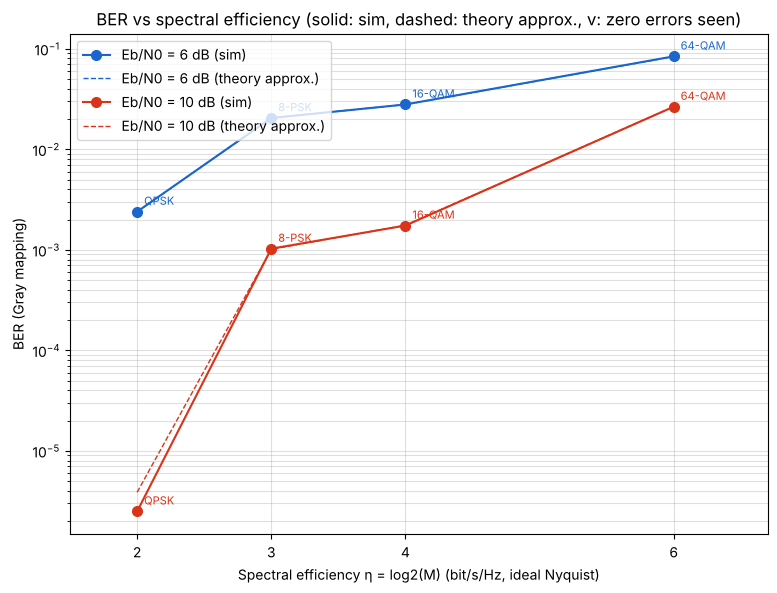

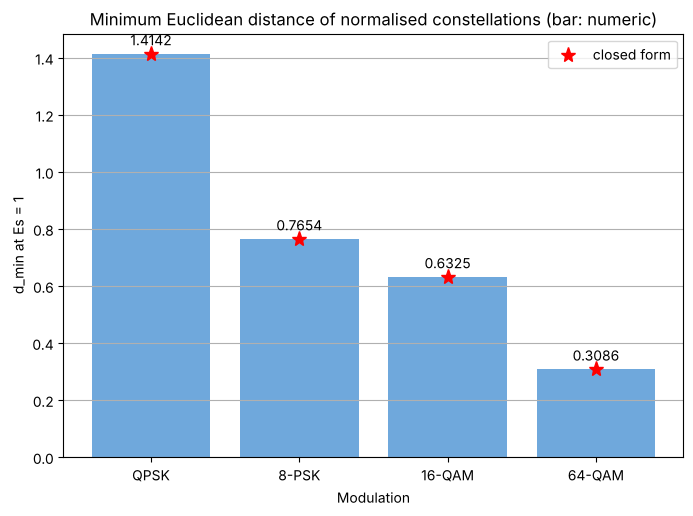


---- d_min, PSK vs QAM at equal M and Es = 1 (numeric) ----
  M | d_min M-PSK | d_min M-QAM | PSK/QAM
 16 |    0.390181 |    0.632456 | 0.6169
 64 |    0.098135 |    0.308607 | 0.3180


In [9]:
print("\n---- SPECTRAL EFFICIENCY (ideal Nyquist, B = Rs, no coding/overhead) ----")
print(f"{'Mod':8s} | {'M':>3s} | Bits/symbol | eta (bit/s/Hz)")
for c in C:
    print(f"{c['name']:8s} | {c['M']:3d} | {c['k']:11d} | {c['k']}")
    check(f"{c['name']}: spectral efficiency uses k = log2(M) = {c['k']}", c["k"] == math.log2(c["M"]))

print(f"\n---- BER vs SPECTRAL EFFICIENCY (Gray; N = {NSYM_SE:g} symbols per point) ----")
BERse = np.zeros((len(EBN0_SE), 4)); Tse = np.zeros_like(BERse)
for q, e in enumerate(EBN0_SE):
    line = f"Eb/N0 = {e:2d} dB : "
    for m, c in enumerate(C):
        b, _, ne, *_ = simulate_link(c["pts"], c["labG"], c["k"], e, NSYM_SE, 4000 + 10 * (q + 1) + m + 1)
        BERse[q, m] = b
        Tse[q, m] = float(theory_curves(c["kind"], c["M"], e)[0])
        line += f"{c['name']} eta={c['k']} BER={b:.3e} (errs {ne}) | "
    print(line)

fig, ax = plt.subplots(figsize=(9, 6.5))
floor = 1 / (NSYM_SE * np.mean(K_LIST))
for q, e in enumerate(EBN0_SE):
    col = ["#1a66cc", "#d93319"][q]
    b = np.maximum(BERse[q], floor)
    ax.semilogy(K_LIST, b, "o-", color=col, lw=1.5, ms=7, label=f"Eb/N0 = {e} dB (sim)")
    ax.semilogy(K_LIST, Tse[q], "--", color=col, lw=1, label=f"Eb/N0 = {e} dB (theory approx.)")
    for m in range(4):
        ax.annotate(NAMES[m], (K_LIST[m], b[m]), textcoords="offset points", xytext=(5, 5), fontsize=8, color=col)
    zero = np.where(BERse[q] == 0)[0]
    ax.plot(np.array(K_LIST)[zero], b[zero], "v", color=col, ms=9)
ax.set_xticks(K_LIST); ax.set_xlim(1.5, 6.7); ax.grid(True, which="both", alpha=0.4)
ax.set_xlabel("Spectral efficiency η = log2(M) (bit/s/Hz, ideal Nyquist)"); ax.set_ylabel("BER (Gray mapping)")
ax.set_title("BER vs spectral efficiency (solid: sim, dashed: theory approx., v: zero errors seen)")
ax.legend(loc="upper left"); savefig(fig, "Fig11_BER_vs_Spectral_Efficiency"); plt.show()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.bar(NAMES, [c["dmin"] for c in C], color="#6fa8dc")
ax.plot(NAMES, [c["dmin_th"] for c in C], "r*", ms=11, label="closed form")
for m, c in enumerate(C):
    ax.text(m, c["dmin"] + 0.03, f"{c['dmin']:.4f}", ha="center")
ax.set_xlabel("Modulation"); ax.set_ylabel("d_min at Es = 1"); ax.grid(True, axis="y"); ax.legend()
ax.set_title("Minimum Euclidean distance of normalised constellations (bar: numeric)")
savefig(fig, "Fig12_dmin_comparison"); plt.show()

print("\n---- d_min, PSK vs QAM at equal M and Es = 1 (numeric) ----")
print("  M | d_min M-PSK | d_min M-QAM | PSK/QAM")
for Mc in (16, 64):
    dP = calculate_dmin(normalize_constellation(generate_mpsk(Mc, 1.0, 0.0), 1)[0])[0]
    dQ = calculate_dmin(normalize_constellation(generate_qam(Mc), 1)[0])[0]
    print(f"{Mc:3d} | {dP:11.6f} | {dQ:11.6f} | {dP / dQ:.4f}")
    check(f"Equal M={Mc}, equal Es: d_min(PSK) < d_min(QAM)", dP < dQ)

## Final validation checklist

In [10]:
i10 = int(np.where(EBN0_DB == 10)[0][0])
check("BER at Eb/N0=10 dB rises with M within QAM: QPSK <= 16-QAM <= 64-QAM",
      BERg[0, i10] <= BERg[2, i10] <= BERg[3, i10])
check("Equal Es: d_min falls as M rises (QPSK > 8-PSK, 16-QAM > 64-QAM)",
      C[0]["dmin"] > C[1]["dmin"] and C[2]["dmin"] > C[3]["dmin"])
# every symbol error causes between 1 and k bit errors: SER <= k*BER <= k*SER
c_ok = all(np.all(SERg[m] <= C[m]["k"] * BERg[m] + 1e-12) and np.all(C[m]["k"] * BERg[m] <= C[m]["k"] * SERg[m] + 1e-12)
           for m in range(4))
check("Independent counters obey SER <= k*BER <= k*SER at every SNR", c_ok)

print("\n---- VALIDATION CHECKLIST ----")
for text, ok in CHECKS:
    print(f"[{'PASS' if ok else 'FAIL'}] {text}")
n_fail = sum(not ok for _, ok in CHECKS)
print(f"\n{len(CHECKS)} checks, {n_fail} failed.   Total run time {time.time() - T0:.1f} s")


---- VALIDATION CHECKLIST ----
[PASS] QPSK has exactly 4 points
[PASS] QPSK all points distinct (d_min>0)
[PASS] QPSK Gray/binary labels are permutations of 0..M-1
[PASS] 8-PSK has exactly 8 points
[PASS] 8-PSK all points distinct (d_min>0)
[PASS] 8-PSK Gray/binary labels are permutations of 0..M-1
[PASS] 16-QAM has exactly 16 points
[PASS] 16-QAM all points distinct (d_min>0)
[PASS] 16-QAM Gray/binary labels are permutations of 0..M-1
[PASS] 64-QAM has exactly 64 points
[PASS] 64-QAM all points distinct (d_min>0)
[PASS] 64-QAM Gray/binary labels are permutations of 0..M-1
[PASS] QPSK: Es after normalisation = 1 (tol 1e-12)
[PASS] QPSK: numeric Es/factor match analytic (tol 1e-12)
[PASS] 8-PSK: Es after normalisation = 1 (tol 1e-12)
[PASS] 8-PSK: numeric Es/factor match analytic (tol 1e-12)
[PASS] 16-QAM: Es after normalisation = 1 (tol 1e-12)
[PASS] 16-QAM: numeric Es/factor match analytic (tol 1e-12)
[PASS] 64-QAM: Es after normalisation = 1 (tol 1e-12)
[PASS] 64-QAM: numeric Es/fac